# Experiment 8: Music Generation using a Recurrent Neural Network (RNN)

## Aim
To build a **Recurrent Neural Network (RNN)** that learns patterns from existing musical note sequences and generates a new musical composition.

## Learning Objectives
After completing this experiment, students should be able to:

- Understand why RNNs are useful for sequential data.
- Represent music as a sequence of notes.
- Prepare input-output sequences for RNN training.
- Build and train a simple RNN using TensorFlow/Keras.
- Generate a new sequence of musical notes.
- Understand the role of **temperature** in controlling creativity.

> **Level:** B.Tech / introductory Deep Learning laboratory

---

## Theory

Music is sequential. A note appearing now often depends on notes that appeared earlier.

An RNN processes a sequence one element at a time while maintaining a hidden state:

\[
h_t = f(W_x x_t + W_h h_{t-1} + b)
\]

where:

- \(x_t\) = current input note
- \(h_{t-1}\) = previous hidden state
- \(h_t\) = current hidden state
- \(W_x, W_h\) = trainable weights

For music generation, the network learns:

**Previous notes → Probability of the next note**

During generation, the predicted next note is appended to the sequence and fed back into the RNN.

## Dataset Format

For easy classroom demonstration, music is represented as text tokens such as:

`C4 D4 E4 F4 G4 A4 B4`

Here:

- `C4` means note C in octave 4.
- `D4` means note D in octave 4.
- `REST` represents silence.

The notebook includes a small built-in teaching corpus based on familiar Western note patterns.

### Using a larger dataset
You may replace the built-in corpus with note sequences extracted from MIDI datasets such as **MAESTRO**, **Nottingham**, or your own MIDI collection.

For a first laboratory experiment, the compact corpus keeps training fast and the code easy to understand.

In [1]:
# Step 1: Import required libraries

import numpy as np
import matplotlib.pyplot as plt

try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    print("TensorFlow version:", tf.__version__)
except ImportError:
    raise ImportError(
        "TensorFlow is required for this notebook. "
        "Install it using: pip install tensorflow"
    )

np.random.seed(42)
tf.random.set_seed(42)

TensorFlow version: 2.20.0


## Step 2: Create / Load Musical Note Sequences

In a real project, notes would normally be extracted from MIDI files.

For this teaching experiment, we use a compact note corpus so that students can understand the complete workflow without complicated MIDI preprocessing.

In [2]:
# A small educational corpus of note sequences.
# These are simplified note patterns for demonstrating sequence learning.

melodies = [
    "C4 C4 G4 G4 A4 A4 G4",
    "F4 F4 E4 E4 D4 D4 C4",
    "G4 G4 F4 F4 E4 E4 D4",
    "G4 G4 F4 F4 E4 E4 D4",
    "C4 C4 G4 G4 A4 A4 G4",
    "F4 F4 E4 E4 D4 D4 C4",

    "C4 D4 E4 F4 G4 G4 G4",
    "A4 A4 A4 G4 F4 F4 F4",
    "E4 E4 E4 D4 C4 C4 C4",

    "E4 D4 C4 D4 E4 E4 E4",
    "D4 D4 D4 E4 G4 G4",
    "E4 D4 C4 D4 E4 E4 E4",
    "E4 D4 D4 E4 D4 C4",

    "C4 E4 G4 C5 G4 E4 C4",
    "D4 F4 A4 D5 A4 F4 D4",
    "E4 G4 B4 E5 B4 G4 E4",

    "C4 REST C4 D4 E4 REST E4",
    "F4 G4 A4 G4 F4 E4 D4 C4"
]

print("Number of melody sequences:", len(melodies))
print("\nExample melody:")
print(melodies[0])

Number of melody sequences: 18

Example melody:
C4 C4 G4 G4 A4 A4 G4


## Step 3: Tokenize the Notes

Neural networks work with numbers, not text.

Therefore, each unique note is assigned an integer ID.

Example:

- `C4 → 0`
- `D4 → 1`
- `E4 → 2`

The exact mapping depends on the vocabulary discovered in the dataset.

In [3]:
# Convert melodies into lists of note tokens
tokenized_melodies = [melody.split() for melody in melodies]

# Build note vocabulary
all_notes = sorted(set(note for melody in tokenized_melodies for note in melody))

note_to_int = {note: i for i, note in enumerate(all_notes)}
int_to_note = {i: note for note, i in note_to_int.items()}

print("Unique notes:", len(all_notes))
print("\nVocabulary:")
print(note_to_int)

Unique notes: 11

Vocabulary:
{'A4': 0, 'B4': 1, 'C4': 2, 'C5': 3, 'D4': 4, 'D5': 5, 'E4': 6, 'E5': 7, 'F4': 8, 'G4': 9, 'REST': 10}


## Step 4: Prepare Training Sequences

Suppose the sequence is:

`C4 D4 E4 F4 G4`

Using a sequence length of 4:

- Input: `C4 D4 E4 F4`
- Target: `G4`

The network learns to predict the **next note** from previous notes.

In [4]:
SEQUENCE_LENGTH = 4

X = []
y = []

for melody in tokenized_melodies:
    encoded = [note_to_int[note] for note in melody]

    if len(encoded) <= SEQUENCE_LENGTH:
        continue

    for i in range(len(encoded) - SEQUENCE_LENGTH):
        X.append(encoded[i:i + SEQUENCE_LENGTH])
        y.append(encoded[i + SEQUENCE_LENGTH])

X = np.array(X)
y = np.array(y)

print("Input shape :", X.shape)
print("Target shape:", y.shape)

print("\nExample training pair:")
print("Input integers :", X[0])
print("Input notes    :", [int_to_note[i] for i in X[0]])
print("Target integer :", y[0])
print("Target note    :", int_to_note[y[0]])

Input shape : (53, 4)
Target shape: (53,)

Example training pair:
Input integers : [2 2 9 9]
Input notes    : ['C4', 'C4', 'G4', 'G4']
Target integer : 0
Target note    : A4


## Step 5: Build the RNN Model

The model contains:

1. **Embedding Layer**  
   Converts each note ID into a dense vector representation.

2. **SimpleRNN Layer**  
   Processes the note sequence and remembers previous information.

3. **Dense Softmax Layer**  
   Produces a probability distribution over all possible next notes.

In [5]:
VOCAB_SIZE = len(all_notes)

model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=16,
        input_length=SEQUENCE_LENGTH
    ),

    SimpleRNN(
        units=64,
        activation='tanh'
    ),

    Dense(
        VOCAB_SIZE,
        activation='softmax'
    )
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## Step 6: Train the RNN

For classroom use, we keep the number of epochs moderate.

You may increase the number of epochs for better learning.

In [6]:
EPOCHS = 100
BATCH_SIZE = 16

history = model.fit(
    X,
    y,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=0
)

print("Training completed.")
print("Final training accuracy:", round(history.history['accuracy'][-1], 4))

Training completed.
Final training accuracy: 0.9811


## Step 7: Plot Training Performance

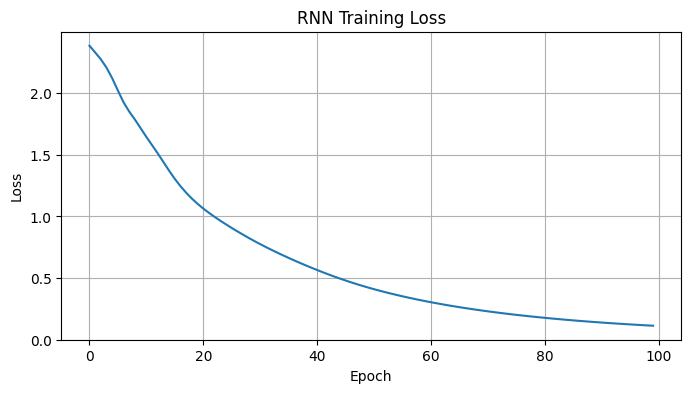

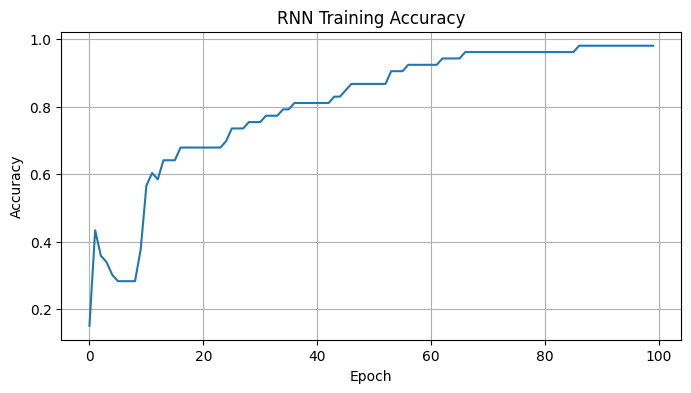

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN Training Loss")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'])
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("RNN Training Accuracy")
plt.grid(True)
plt.show()

## Step 8: Generate New Music

The RNN predicts a probability for each possible next note.

Instead of always selecting the most probable note, we can sample from the probability distribution.

### Temperature

Temperature controls the randomness of generation:

- **Low temperature (e.g. 0.5):** safer and more repetitive.
- **Temperature = 1.0:** balanced.
- **High temperature (e.g. 1.5):** more creative and unpredictable.

In [8]:
def sample_with_temperature(probabilities, temperature=1.0):
    probabilities = np.asarray(probabilities).astype("float64")

    # Avoid log(0)
    probabilities = np.log(probabilities + 1e-8) / temperature
    probabilities = np.exp(probabilities)
    probabilities = probabilities / np.sum(probabilities)

    return np.random.choice(len(probabilities), p=probabilities)


def generate_music(model, seed_notes, num_notes=30, temperature=1.0):
    current_sequence = [note_to_int[note] for note in seed_notes]

    if len(current_sequence) != SEQUENCE_LENGTH:
        raise ValueError(
            f"Seed must contain exactly {SEQUENCE_LENGTH} notes."
        )

    generated_notes = list(seed_notes)

    for _ in range(num_notes):
        input_sequence = np.array(current_sequence[-SEQUENCE_LENGTH:]).reshape(1, -1)

        probabilities = model.predict(input_sequence, verbose=0)[0]
        predicted_id = sample_with_temperature(probabilities, temperature)
        predicted_note = int_to_note[predicted_id]

        generated_notes.append(predicted_note)
        current_sequence.append(predicted_id)

    return generated_notes

## Step 9: Generate a New Composition

In [9]:
seed = ["C4", "D4", "E4", "F4"]

generated_notes = generate_music(
    model,
    seed_notes=seed,
    num_notes=30,
    temperature=0.8
)

print("Generated Musical Composition:\n")
print(" ".join(generated_notes))

Generated Musical Composition:

C4 D4 E4 F4 G4 G4 G4 F4 E4 E4 C4 D4 C4 E4 E4 E4 G4 C4 C4 B4 E4 E4 E4 C4 C4 C4 E4 E4 E4 G4 C4 C4 B4 E4


## Step 10: Compare Different Temperature Values

In [10]:
temperatures = [0.5, 1.0, 1.5]

for temp in temperatures:
    generated = generate_music(
        model,
        seed_notes=["C4", "D4", "E4", "F4"],
        num_notes=20,
        temperature=temp
    )

    print(f"\nTemperature = {temp}")
    print(" ".join(generated))


Temperature = 0.5
C4 D4 E4 F4 G4 G4 G4 F4 G4 E4 C4 D4 C4 E4 E4 E4 C4 C4 C4 E4 E4 E4 E4 C4

Temperature = 1.0
C4 D4 E4 F4 G4 G4 G4 F4 G4 E4 C4 D4 C4 C4 E4 E4 E4 E4 C4 C4 C4 E4 E4 E4

Temperature = 1.5
C4 D4 E4 F4 G4 G4 A4 F4 G4 E4 D4 D4 C4 C4 G4 E4 A4 A4 G4 B4 F4 F4 G4 E4


## Step 11: Optional MIDI Export

If the `music21` package is installed, the generated note sequence can be saved as a MIDI file.

Install it using:

`pip install music21`

This step is optional and is not required to understand the RNN.

In [11]:
# Optional MIDI export

try:
    from music21 import note, stream

    music_stream = stream.Stream()

    for token in generated_notes:
        if token == "REST":
            music_stream.append(note.Rest(quarterLength=1.0))
        else:
            music_stream.append(note.Note(token, quarterLength=1.0))

    midi_filename = "generated_rnn_music.mid"
    music_stream.write("midi", fp=midi_filename)

    print("MIDI file created:", midi_filename)

except ImportError:
    print(
        "music21 is not installed. MIDI export skipped.\n"
        "Install it with: pip install music21"
    )

MIDI file created: generated_rnn_music.mid


# Observations

Students should observe that:

- The loss generally decreases during training.
- The training accuracy generally increases.
- The generated sequence contains note patterns learned from the training data.
- Lower temperature produces more predictable output.
- Higher temperature introduces greater randomness.

---

# Result

A **Recurrent Neural Network (RNN)** was successfully designed to learn sequential patterns from musical note sequences and generate a new composition.

The experiment demonstrates that RNNs can model temporal dependencies and can be used for sequence-generation tasks such as:

- Music generation
- Text generation
- Speech processing
- Time-series prediction

---

# Viva / Discussion Questions

1. Why is music considered sequential data?
2. What is the role of the hidden state in an RNN?
3. Why do we convert notes into integer IDs?
4. What does the embedding layer do?
5. Why is softmax used in the output layer?
6. What is the difference between training and music generation?
7. What is temperature in sequence generation?
8. What happens when temperature is very low?
9. What limitation does a simple RNN have for long sequences?
10. Why are LSTM and GRU often preferred over a basic RNN for complex music generation?

---

# Suggested Extension Exercises

Students may extend this experiment by:

- Replacing `SimpleRNN` with an **LSTM**.
- Replacing `SimpleRNN` with a **GRU**.
- Increasing the size of the music dataset.
- Extracting notes from real MIDI files.
- Including note duration along with pitch.
- Generating chords in addition to individual notes.
- Comparing RNN, LSTM and GRU performance.